# 02 — Time-Series EDA

## Reproducibility and setup
The first code cell locates the project folder from the current directory or the configured Windows path.
The datasets are synthetic teaching data generated with a fixed random seed. Findings are practice examples, not claims about a real business.

Questions: Is there a trend? Are there weekly patterns? Which dates look anomalous? Are dates complete?

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents, Path(r"E:\Linkific\Day 7")):
    if (candidate / "src" / "__init__.py").is_file() and (candidate / "data" / "raw").is_dir():
        PROJECT_ROOT = candidate.resolve()
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from E:\\Linkific\\Day 7 "
        "or update the fallback path in this cell."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "time_series.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_quality import quality_summary
from src.profiling import create_profile

sns.set_theme()
df = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date")
df.head()

,date,daily_sales,website_sessions
0,2024-01-01,258.59,1738.0
1,2024-01-02,263.58,1873.0
2,2024-01-03,281.77,1973.0
3,2024-01-04,259.81,2047.0
4,2024-01-05,254.25,1638.0


## 1. Validate time index
Check duplicated dates, sorting, missing dates and null values before resampling or rolling calculations.

In [2]:
print("Shape:", df.shape)
print("Duplicate dates:", df["date"].duplicated().sum())
print("Date range:", df.date.min(), "to", df.date.max())
expected = pd.date_range(df.date.min(), df.date.max(), freq="D")
print("Missing calendar dates:", len(expected.difference(pd.DatetimeIndex(df.date))))
display(quality_summary(df))
df = df.set_index("date").asfreq("D")

Shape: (730, 3)
Duplicate dates: 0
Date range: 2024-01-01 00:00:00 to 2025-12-30 00:00:00
Missing calendar dates: 0


,column,dtype,missing_count,missing_pct,unique_count,duplicate_rows_total
0,date,datetime64[ns],0,0.00,730,0
1,daily_sales,float64,0,0.00,711,0
2,website_sessions,float64,1,0.14,596,0


## 2. Plot trend and variation
Plot raw values first; rolling means smooth short-term variation but can hide local spikes.

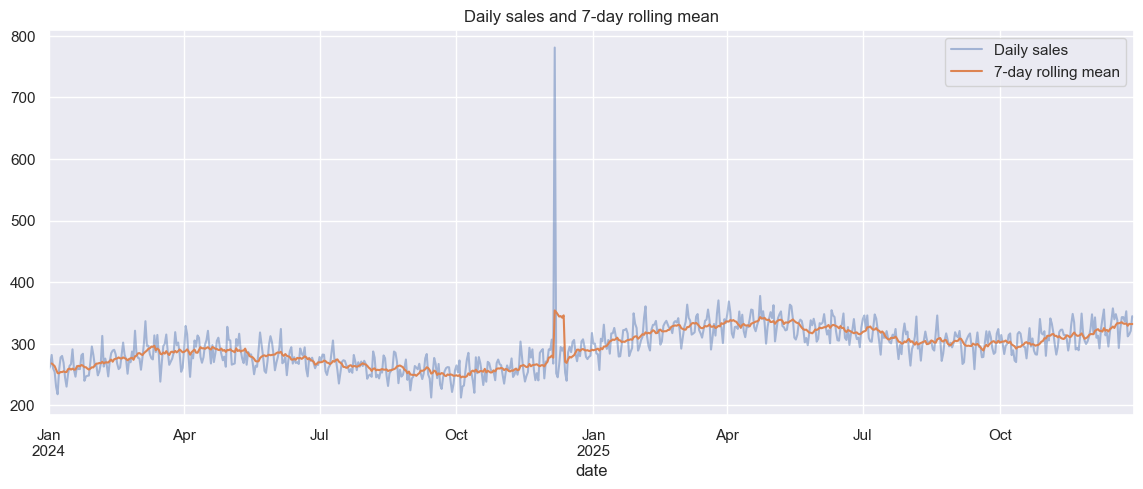

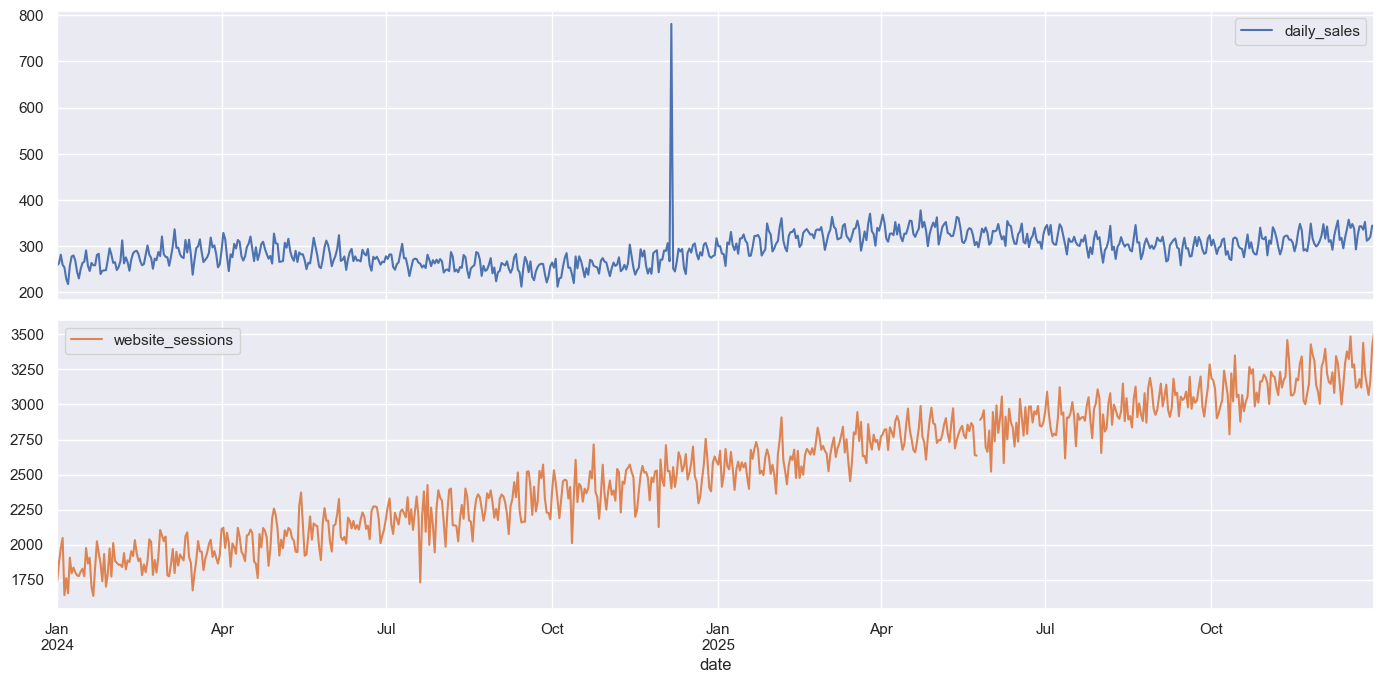

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
df["daily_sales"].plot(ax=ax, alpha=.45, label="Daily sales")
df["daily_sales"].rolling(7, min_periods=3).mean().plot(ax=ax, label="7-day rolling mean")
ax.set_title("Daily sales and 7-day rolling mean")
ax.legend()
plt.show()
df[["daily_sales", "website_sessions"]].plot(subplots=True, figsize=(14, 7))
plt.tight_layout()
plt.show()

## 3. Calendar patterns
Day-of-week and month summaries can reveal seasonality, but interpret cautiously if the dataset spans only a short period.

,count,mean,median,std
day_name,,,,
Monday,105,293.614857,297.880,28.609295
Tuesday,105,308.288190,312.020,28.548959
Wednesday,104,311.654519,313.390,30.035688
Thursday,104,299.363077,299.700,29.153160
Friday,104,290.902365,286.495,57.777557
Saturday,104,276.587981,275.565,28.195806
Sunday,104,279.523269,278.370,27.611371


month
2025-01    304.149355
2025-02    323.003214
2025-03    328.680968
2025-04    335.804667
2025-05    329.344839
2025-06    322.598333
2025-07    314.520968
2025-08    301.200968
2025-09    300.271667
2025-10    301.234194
2025-11    311.453333
2025-12    328.660667
Name: daily_sales, dtype: float64

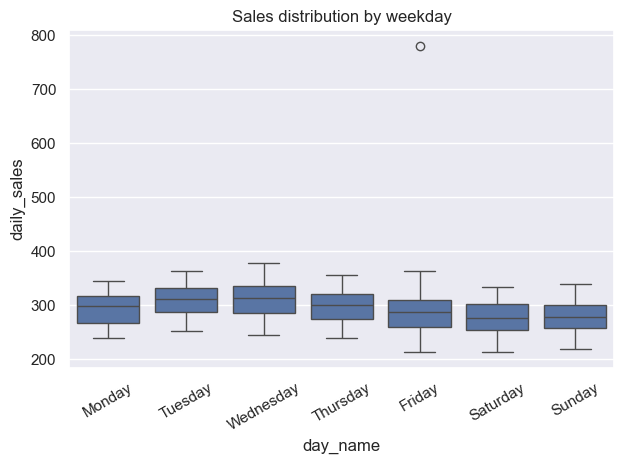

In [4]:
df["day_name"] = df.index.day_name()
df["month"] = df.index.to_period("M").astype(str)
display(df.groupby("day_name")["daily_sales"].agg(["count","mean","median","std"]).reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))
display(df.groupby("month")["daily_sales"].mean().tail(12))
sns.boxplot(data=df.reset_index(), x="day_name", y="daily_sales",
            order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
plt.xticks(rotation=30)
plt.title("Sales distribution by weekday")
plt.tight_layout()
plt.show()

## 4. Anomaly screening
A rolling z-score is a screening signal, not proof of an anomaly. Business events, holidays and instrumentation changes may explain spikes.

,daily_sales,rolling_z,website_sessions
date,,,
2024-11-13,303.540,3.121407,2571.0
2024-12-06,780.976,4.992675,2401.0


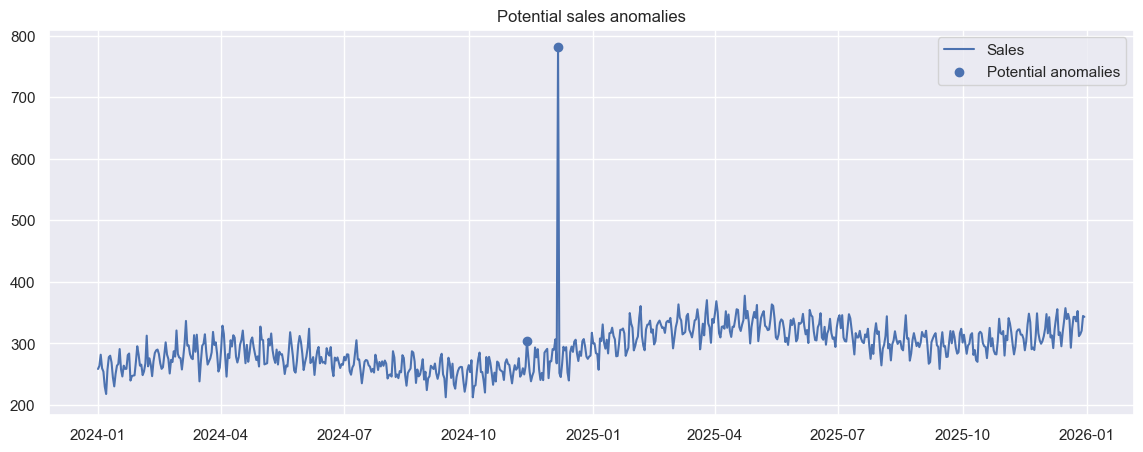

In [5]:
series = df["daily_sales"]
rolling_mean = series.rolling(28, min_periods=14).mean()
rolling_std = series.rolling(28, min_periods=14).std()
df["rolling_z"] = (series - rolling_mean) / rolling_std
anomalies = df[df["rolling_z"].abs() >= 3][["daily_sales","rolling_z","website_sessions"]]
display(anomalies)
plt.figure(figsize=(14, 5))
plt.plot(df.index, series, label="Sales")
plt.scatter(anomalies.index, anomalies["daily_sales"], label="Potential anomalies")
plt.legend()
plt.title("Potential sales anomalies")
plt.show()

## 5. Relationship between sessions and sales
Align observations by date and use complete pairs. Correlation may be influenced by trend or shared seasonality.

,daily_sales,website_sessions
daily_sales,1.000000,0.525917
website_sessions,0.525917,1.000000


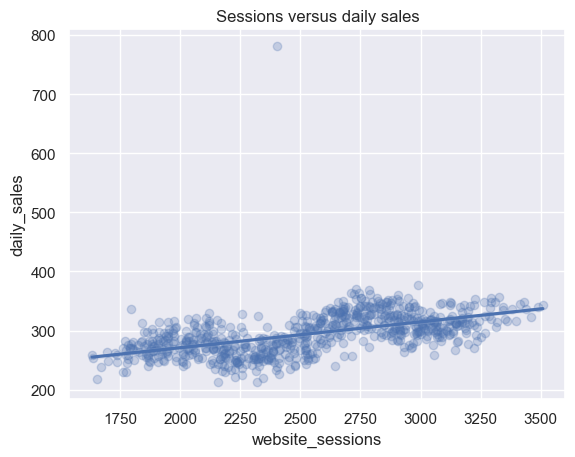

In [6]:
pair = df[["daily_sales","website_sessions"]].dropna()
display(pair.corr())
sns.regplot(data=pair, x="website_sessions", y="daily_sales", scatter_kws={"alpha":.25})
plt.title("Sessions versus daily sales")
plt.show()

## 6. Automated profile

In [7]:
report_path = PROJECT_ROOT / "reports/time_series_profile.html"
create_profile(df.reset_index(), "Time-Series EDA Profile", report_path)
print("Saved:", report_path)

Saved: E:\Linkific\Day 7\reports\time_series_profile.html


C:\Users\niran\AppData\Local\Temp\ipykernel_14904\4273845108.py:2: RuntimeWarning: ydata-profiling is not installed in this Python environment; writing a basic HTML summary instead.
  create_profile(df.reset_index(), "Time-Series EDA Profile", report_path)


## Findings template
Record trend direction, weekday effects, missing dates/values, candidate anomalies, and limitations. State the window and method used for each finding.